In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

# Observe class distribution
class_counts = y.value_counts()
class_names = data.target_names

print("Class Distribution:")
for val, name in enumerate(class_names):
    count = class_counts.get(val, 0)
    percent = (count / len(y)) * 100
    print(f"  Class {val} ({name}): {count} occurrences ({percent:.2f}%)")

# Split into training (75%) and testing (25%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(f"\nTraining set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Class Distribution:
  Class 0 (malignant): 212 occurrences (37.26%)
  Class 1 (benign): 357 occurrences (62.74%)

Training set shape: (426, 30)
Testing set shape: (143, 30)


In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

depths = [2, 3, 4, 5, None]
dt_results = []

for depth in depths:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train, y_train)
    y_pred = dt.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    dt_results.append({
        'max_depth': 'None' if depth is None else depth,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

dt_df = pd.DataFrame(dt_results)
display(dt_df)

,max_depth,Accuracy,Precision,Recall,F1-Score
0,2,0.909091,0.963855,0.888889,0.924855
1,3,0.944056,0.945652,0.966667,0.956044
2,4,0.944056,0.955556,0.955556,0.955556
3,5,0.937063,0.955056,0.944444,0.949721
4,None,0.923077,0.954023,0.922222,0.937853


In [10]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=150, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

rf_results = {
    'Model': 'Random Forest (150 trees)',
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1-Score': f1_score(y_test, y_pred_rf)
}

comparison_df = pd.concat([
    dt_df.assign(Model=lambda df: 'DT (depth=' + df['max_depth'].astype(str) + ')').drop(columns=['max_depth']),
    pd.DataFrame([rf_results])
], ignore_index=True)

display(comparison_df)

,Accuracy,Precision,Recall,F1-Score,Model
0,0.909091,0.963855,0.888889,0.924855,DT (depth=2)
1,0.944056,0.945652,0.966667,0.956044,DT (depth=3)
2,0.944056,0.955556,0.955556,0.955556,DT (depth=4)
3,0.937063,0.955056,0.944444,0.949721,DT (depth=5)
4,0.923077,0.954023,0.922222,0.937853,DT (depth=None)
5,0.958042,0.956522,0.977778,0.967033,Random Forest (150 trees)


In [11]:
best_dt = DecisionTreeClassifier(max_depth=3, random_state=42)
best_dt.fit(X_train, y_train)
y_pred_dt = best_dt.predict(X_test)

print("Decision Tree Confusion Matrix (depth=3):")
print(confusion_matrix(y_test, y_pred_dt))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Decision Tree Confusion Matrix (depth=3):
[[48  5]
 [ 3 87]]

Random Forest Confusion Matrix:
[[49  4]
 [ 2 88]]


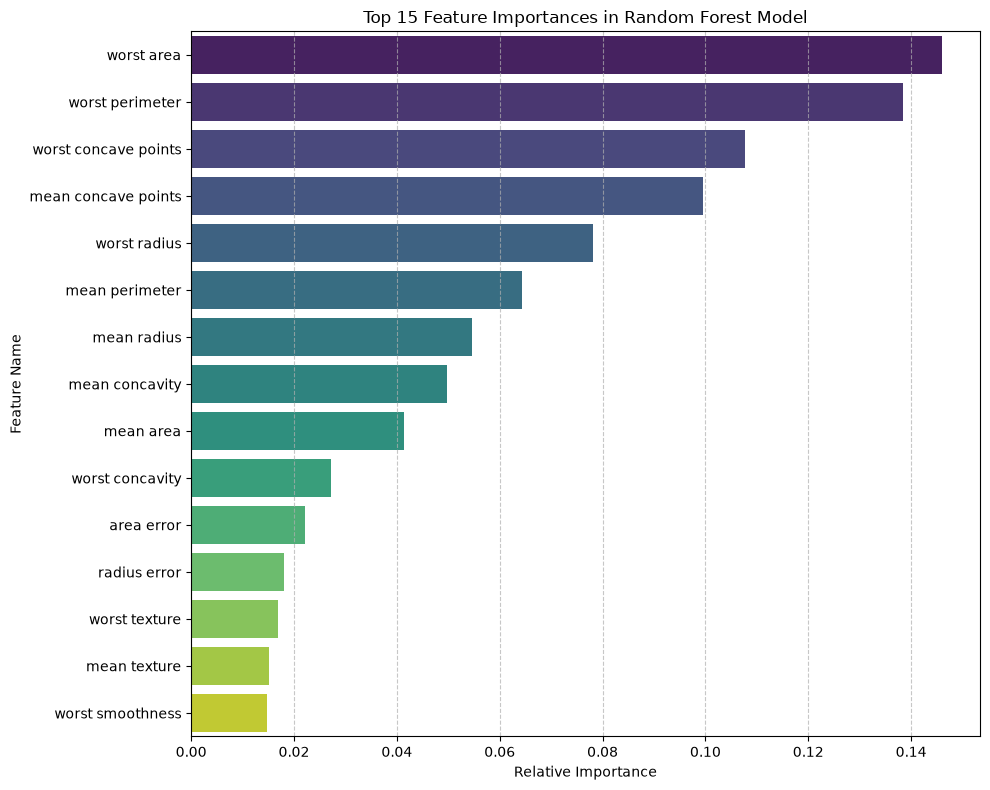

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importances
importances = rf.feature_importances_
features = X.columns

# Create a DataFrame for easy visualization
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot the top 15 features
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(15), palette='viridis', hue='Feature', legend=False, ax=ax)
ax.set_title('Top 15 Feature Importances in Random Forest Model')
ax.set_xlabel('Relative Importance')
ax.set_ylabel('Feature Name')
ax.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()